# 👥 People Analytics: ¿por qué renuncian los empleados y qué puede hacer RR.HH.?
### Cuando el modelo más simple gana: regresión logística interpretable vs. Random Forest y XGBoost, curva de permanencia, palancas de acción y resumen ejecutivo de una página

**Autor:** Cristobal Rojas · **Herramientas:** Python, pandas, scikit-learn, XGBoost, matplotlib

---

## 🎯 Contexto (PACE · Planificar)
El área de Recursos Humanos de una empresa con 1.470 empleados ve que **16 de cada 100 personas renuncian**. Cada salida implica costos de reclutamiento, inducción y productividad perdida. La gerencia pregunta:

1. **¿Qué factores explican la renuncia?** Necesitan respuestas que un comité de personas pueda entender y discutir.
2. **¿Cuáles de esos factores puede cambiar la empresa?** Un modelo que dice "los jóvenes solteros renuncian más" no le sirve a RR.HH.
3. **¿A quién priorizar** para conversaciones de desarrollo y retención?

**Consideraciones éticas desde el inicio**
- El modelo **no** se usará para despedir, bloquear promociones ni decidir contrataciones. Su uso es **identificar condiciones de trabajo que empujan a renunciar** y priorizar conversaciones de apoyo.
- Los puntajes individuales son **confidenciales** y no se comparten con jefaturas directas sin contexto.
- Sexo, edad y estado civil se evalúan como variables **protegidas**: se medirá si hacen falta y se auditará el resultado por grupo.

**Dataset:** [IBM HR Analytics Employee Attrition & Performance — Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) · 1.470 empleados · 35 variables · dataset ficticio creado por científicos de datos de IBM.

## 🧭 Hoja de ruta
| # | Etapa | Qué aporta |
|---|---|---|
| 1 | Auditoría | Columnas constantes y "tarifas" que no son sueldo |
| 2 | EDA + **curva de permanencia** | Cuándo se va la gente, no solo quién |
| 3 | Ingeniería de variables | Sueldo relativo al cargo, estancamiento, rotación previa |
| 4 | **Validación cruzada repetida** | Con 1.470 filas, un solo split puede engañar |
| 5 | Logística vs. Random Forest vs. XGBoost | El modelo más simple gana |
| 6 | **Odds ratios con intervalos de confianza** y VIF | Interpretación que entiende un comité |
| 7 | **Palancas accionables** y costo de la rotación | Qué puede cambiar la empresa y cuánto vale |
| 8 | Auditoría de equidad | ¿Hacen falta sexo, edad o estado civil? |
| 9 | **Resumen ejecutivo de una página** | El entregable para la gerencia |

In [1]:
# ==== Importaciones ====
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
SEED = 7
IMG = Path("../images"); IMG.mkdir(parents=True, exist_ok=True)
REP = Path("../reports"); REP.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, VERDE, VIOLETA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#8a8984"
TINTA, TINTA2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
})
PCT = plt.FuncFormatter(lambda x, _: f"{x:.0%}")

def es(x, dec=0):
    """Formato numérico chileno: 1.234,5"""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def guardar(nombre):
    plt.savefig(IMG / f"{nombre}.png", facecolor="white")
    plt.show()

## 1. Carga y auditoría (PACE · Analizar)

In [2]:
RUTA_LOCAL = Path("../data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
URL_RESPALDO = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"
df_original = pd.read_csv(RUTA_LOCAL if RUTA_LOCAL.exists() else URL_RESPALDO, encoding="utf-8-sig")
print(f"Empleados: {es(len(df_original))} | Variables: {df_original.shape[1]} | "
      f"Faltantes: {df_original.isna().sum().sum()} | Duplicados: {df_original.duplicated().sum()}")
df_original.head()

Empleados: 1.470 | Variables: 35 | Faltantes: 0 | Duplicados: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
constantes = [c for c in df_original.columns if df_original[c].nunique() == 1]
print("Columnas constantes (no aportan información):", constantes)

tarifas = ["DailyRate", "HourlyRate", "MonthlyRate"]
corr = df_original[["MonthlyIncome"] + tarifas].corr(method="spearman")["MonthlyIncome"].drop("MonthlyIncome")
print("\nCorrelación de Spearman con el sueldo mensual (MonthlyIncome):")
print(corr.round(3))
print("\nCorrelación sueldo ↔ nivel de cargo:",
      round(df_original[["MonthlyIncome", "JobLevel"]].corr(method="spearman").iloc[0, 1], 3))

Columnas constantes (no aportan información): ['EmployeeCount', 'Over18', 'StandardHours']

Correlación de Spearman con el sueldo mensual (MonthlyIncome):
DailyRate      0.016
HourlyRate    -0.020
MonthlyRate    0.054
Name: MonthlyIncome, dtype: float64

Correlación sueldo ↔ nivel de cargo: 0.92


**Hallazgos de la auditoría:**
- `EmployeeCount`, `Over18` y `StandardHours` son **constantes**: se eliminan. `EmployeeNumber` es un identificador.
- `DailyRate`, `HourlyRate` y `MonthlyRate` **no tienen relación con el sueldo** (correlación ≈ 0), mientras que `MonthlyIncome` sí sigue al nivel del cargo (0,92). Por su nombre parecen remuneraciones, pero en este dataset ficticio se comportan como ruido. Usarlas como "sueldo" llevaría a conclusiones falsas, así que se excluyen y el análisis salarial se hace con `MonthlyIncome`.

Revisar si una variable *significa* lo que su nombre sugiere es tan importante como revisar nulos.

In [4]:
df = df_original.drop(columns=constantes + tarifas + ["EmployeeNumber"]).copy()
df["renuncia"] = (df.pop("Attrition") == "Yes").astype(int)
print(f"Variables útiles: {df.shape[1] - 1} | Tasa de renuncia: {df['renuncia'].mean():.1%}")

Variables útiles: 27 | Tasa de renuncia: 16.1%


## 2. Análisis exploratorio
### 2.1 Curva de permanencia: ¿cuándo se van?
Una curva de **Kaplan-Meier** (análisis de supervivencia) estima la probabilidad de seguir en la empresa según los años transcurridos. Se calcula a mano con `numpy`: quienes siguen en la empresa son observaciones **censuradas** (aún no sabemos cuándo se irán).

Renuncias que ocurren en los primeros 2 años de antigüedad: 43%


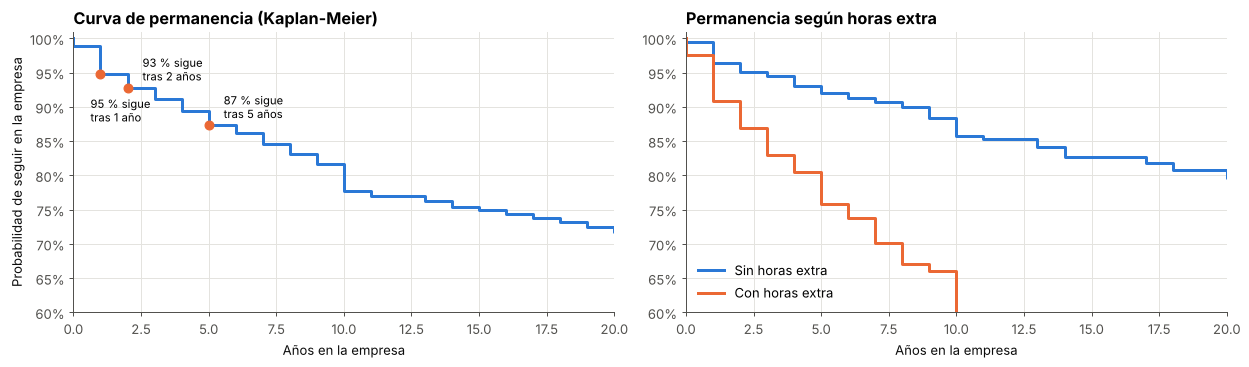

In [5]:
def kaplan_meier(tiempo, evento):
    tiempos = np.sort(np.unique(tiempo[evento == 1]))
    s, curva = 1.0, [(0, 1.0)]
    for t in tiempos:
        en_riesgo = (tiempo >= t).sum()
        eventos = ((tiempo == t) & (evento == 1)).sum()
        s *= 1 - eventos / en_riesgo
        curva.append((t, s))
    return np.array(curva)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
t_, e_ = df["YearsAtCompany"].values, df["renuncia"].values
km = kaplan_meier(t_, e_)
ax = axes[0]
ax.step(km[:, 0], km[:, 1], where="post", color=AZUL, lw=2.4)
for anio, off in [(1, (-8, -38)), (2, (12, 6)), (5, (12, 6))]:
    s = km[km[:, 0] <= anio, 1][-1]
    ax.plot(anio, s, "o", color=NARANJA, ms=7)
    ax.annotate(f"{s*100:.0f} % sigue\ntras {anio} año{'s' if anio > 1 else ''}", (anio, s),
                xytext=off, textcoords="offset points", fontsize=9)
ax.set_xlim(0, 20); ax.set_ylim(0.6, 1.01); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Años en la empresa"); ax.set_ylabel("Probabilidad de seguir en la empresa")
ax.set_title("Curva de permanencia (Kaplan-Meier)")

ax = axes[1]
for valor, color, nombre in [("No", AZUL, "Sin horas extra"), ("Yes", NARANJA, "Con horas extra")]:
    m = (df["OverTime"] == valor).values
    k = kaplan_meier(t_[m], e_[m])
    ax.step(k[:, 0], k[:, 1], where="post", color=color, lw=2.4, label=nombre)
ax.set_xlim(0, 20); ax.set_ylim(0.6, 1.01); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Años en la empresa"); ax.set_title("Permanencia según horas extra"); ax.legend(loc="lower left")
plt.tight_layout()
guardar("01_curva_permanencia")
print(f"Renuncias que ocurren en los primeros 2 años de antigüedad: "
      f"{(df.loc[df.renuncia == 1, 'YearsAtCompany'] <= 2).mean():.0%}")

> **Supuesto:** el dataset es una foto y `YearsAtCompany` es la antigüedad al momento de renunciar (o la actual, para quienes siguen). La curva es una aproximación útil para ver **cuándo** se concentra el riesgo.

**El riesgo se concentra en los primeros años**, y la brecha entre quienes hacen horas extra y quienes no aparece desde el primer año y se mantiene. La **inducción y los primeros 24 meses** son el momento crítico.

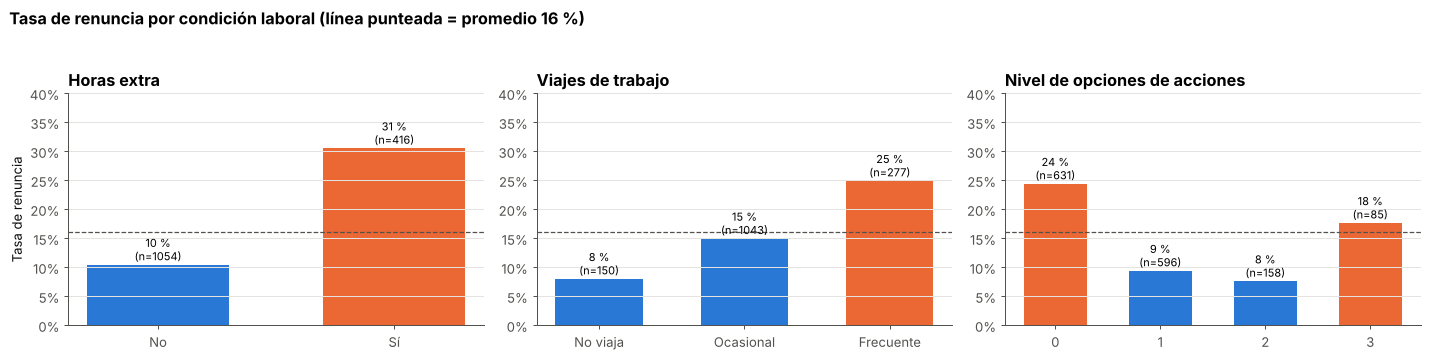

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
paneles = [("OverTime", "Horas extra", {"No": "No", "Yes": "Sí"}),
           ("BusinessTravel", "Viajes de trabajo", {"Non-Travel": "No viaja", "Travel_Rarely": "Ocasional", "Travel_Frequently": "Frecuente"}),
           ("StockOptionLevel", "Nivel de opciones de acciones", None)]
media = df["renuncia"].mean()
for ax, (col, titulo, mapa) in zip(axes, paneles):
    t = df.groupby(col)["renuncia"].agg(["mean", "size"])
    if mapa: t = t.loc[list(mapa)].rename(index=mapa)
    ax.bar(range(len(t)), t["mean"], color=[NARANJA if v > media else AZUL for v in t["mean"]], width=0.6)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m + 0.008, f"{m*100:.0f} %\n(n={n})", ha="center", fontsize=8.8)
    ax.axhline(media, color=TINTA2, ls="--", lw=1)
    ax.set_xticks(range(len(t)), [str(i) for i in t.index]); ax.set_ylim(0, 0.4)
    ax.yaxis.set_major_formatter(PCT); ax.grid(axis="x", visible=False); ax.set_title(titulo)
axes[0].set_ylabel("Tasa de renuncia")
fig.suptitle(f"Tasa de renuncia por condición laboral (línea punteada = promedio {media*100:.0f} %)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
plt.tight_layout()
guardar("02_eda_condiciones")

**Hallazgos:** las **horas extra triplican** la tasa de renuncia (31 % vs. 10 %), los **viajes frecuentes** la triplican frente a quienes no viajan, y no tener **opciones de acciones** (nivel 0) también la eleva. Son condiciones que la empresa **sí puede gestionar**.

## 3. Ingeniería de variables (PACE · Construir)
- `sueldo_relativo_cargo`: sueldo / mediana del sueldo de su nivel de cargo (¿gana menos que sus pares?).
- `estancamiento`: años desde la última promoción / años en la empresa.
- `rotacion_previa`: empresas anteriores / años de experiencia (historial de cambios frecuentes).
- `satisfaccion_total`: promedio de satisfacción con el ambiente, el trabajo, las relaciones y el equilibrio vida-trabajo.

In [7]:
datos = df.copy()
datos["sueldo_relativo_cargo"] = datos["MonthlyIncome"] / datos.groupby("JobLevel")["MonthlyIncome"].transform("median")
datos["estancamiento"] = datos["YearsSinceLastPromotion"] / datos["YearsAtCompany"].clip(lower=1)
datos["rotacion_previa"] = datos["NumCompaniesWorked"] / datos["TotalWorkingYears"].clip(lower=1)
datos["satisfaccion_total"] = datos[["EnvironmentSatisfaction", "JobSatisfaction",
                                     "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)
datos["horas_extra"] = (datos.pop("OverTime") == "Yes").astype(int)
datos["es_mujer"] = (datos.pop("Gender") == "Female").astype(int)
viajes = {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}
datos["viajes"] = datos.pop("BusinessTravel").map(viajes)
datos = pd.get_dummies(datos, columns=["Department", "EducationField", "JobRole", "MaritalStatus"], drop_first=True, dtype=int)
y = datos.pop("renuncia")
X = datos
protegidas = ["Age", "es_mujer"] + [c for c in X.columns if c.startswith("MaritalStatus_")]
print("Variables:", X.shape[1], "| Protegidas:", protegidas)

Variables: 44 | Protegidas: ['Age', 'es_mujer', 'MaritalStatus_Married', 'MaritalStatus_Single']


## 4. Validación cruzada repetida: con pocos datos, un solo split puede engañar
Con 1.470 empleados y solo 237 renuncias, el resultado de **una** división 80/20 depende mucho de qué personas caen en la prueba. Se usa **validación cruzada estratificada de 5 particiones repetida 10 veces** (50 evaluaciones) para medir el rendimiento **y su variabilidad**.

In [8]:
modelos = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000)),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt",
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.6,
                             min_child_weight=3, reg_lambda=5, scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
                             eval_metric="logloss", random_state=SEED, n_jobs=-1),
}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
aucs = {n: cross_val_score(m, X, y, cv=rcv, scoring="roc_auc", n_jobs=1) for n, m in modelos.items()}
resumen = pd.DataFrame({n: {"ROC-AUC medio": v.mean(), "Desv. estándar": v.std(), "Mínimo": v.min(), "Máximo": v.max()}
                        for n, v in aucs.items()}).T.round(3)
resumen.to_csv(REP / "comparacion_modelos_cv.csv")
resumen

,ROC-AUC medio,Desv. estándar,Mínimo,Máximo
Regresión logística,0.835,0.038,0.739,0.894
Random Forest,0.814,0.039,0.712,0.886
XGBoost,0.824,0.036,0.749,0.905


La logística supera a RF en 80% de las particiones y a XGBoost en 64%


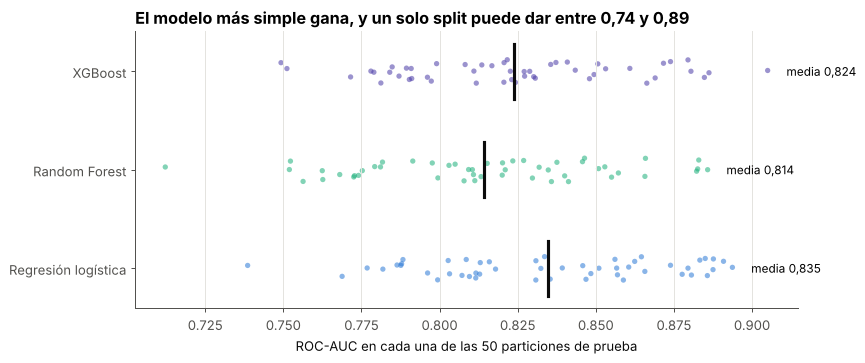

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 4))
cols_m = [AZUL, VERDE, VIOLETA]
for i, ((n, v), c) in enumerate(zip(aucs.items(), cols_m)):
    jitter = np.random.default_rng(SEED).uniform(-0.12, 0.12, len(v))
    ax.scatter(v, np.full(len(v), i) + jitter, s=18, color=c, alpha=0.55, edgecolor="none")
    ax.plot([v.mean()] * 2, [i - 0.28, i + 0.28], color=TINTA, lw=2.5)
    ax.text(v.max() + 0.006, i, f"media {es(v.mean(), 3)}", va="center", fontsize=9.5)
ax.set_yticks(range(len(aucs)), list(aucs.keys())); ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC en cada una de las 50 particiones de prueba")
ax.set_title("El modelo más simple gana, y un solo split puede dar entre 0,74 y 0,89")
guardar("03_validacion_repetida")

lr_vs = [(aucs["Regresión logística"] > aucs[n]).mean() for n in ["Random Forest", "XGBoost"]]
print(f"La logística supera a RF en {lr_vs[0]:.0%} de las particiones y a XGBoost en {lr_vs[1]:.0%}")

**Lección doble:**
1. **La regresión logística, el modelo más simple, rinde igual o mejor** que Random Forest y XGBoost. Con pocos datos y relaciones mayormente monótonas (más horas extra → más riesgo), los modelos complejos no tienen de dónde sacar ventaja y tienden a sobreajustar.
2. **Un único split puede dar un ROC-AUC entre 0,74 y 0,89** para el mismo modelo, según qué empleados caigan en la prueba. Reportar un solo número con 1.470 filas sería engañoso: con otra semilla, la conclusión sobre qué modelo es mejor podría invertirse.

Como la logística además es **la más interpretable**, es el modelo elegido.

## 5. Interpretación: odds ratios con intervalos de confianza
El **odds ratio (OR)** dice cuánto se multiplican las chances de renunciar cuando la variable aumenta en **1 desviación estándar** (o pasa de 0 a 1 en las binarias), manteniendo el resto constante. Los intervalos de 95 % se calculan con **bootstrap** (300 remuestreos), sin librerías adicionales.

Antes se verifica un supuesto clave de la regresión logística: **baja multicolinealidad (VIF)**.

In [10]:
def vif(Xdf):
    Z = (Xdf - Xdf.mean()) / Xdf.std()
    out = {}
    for c in Z.columns:
        otros = np.c_[np.ones(len(Z)), Z.drop(columns=c).values]
        coef, *_ = np.linalg.lstsq(otros, Z[c].values, rcond=None)
        r2 = 1 - ((Z[c].values - otros @ coef) ** 2).sum() / (Z[c].values ** 2).sum()
        out[c] = 1 / max(1 - r2, 1e-6)
    return pd.Series(out).sort_values(ascending=False)

numericas = ["Age", "MonthlyIncome", "JobLevel", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
             "YearsWithCurrManager", "YearsSinceLastPromotion", "NumCompaniesWorked", "DistanceFromHome",
             "sueldo_relativo_cargo", "estancamiento", "rotacion_previa", "satisfaccion_total"]
v = vif(X[numericas])
print("VIF (> 5 indica multicolinealidad problemática):"); print(v.round(1).head(6))

VIF (> 5 indica multicolinealidad problemática):
MonthlyIncome              29.2
JobLevel                   28.6
TotalWorkingYears           5.9
YearsAtCompany              5.5
YearsSinceLastPromotion     3.6
rotacion_previa             3.2
dtype: float64


`MonthlyIncome` y `JobLevel` están casi duplicadas (el sueldo depende del nivel), y las variables de años están muy relacionadas entre sí. Para el modelo **interpretable** se reduce la redundancia: se conserva `JobLevel` + `sueldo_relativo_cargo` (en vez del sueldo absoluto), y `YearsAtCompany` + `estancamiento` (en vez de 4 variables de años).

VIF máximo tras depurar: 1.56


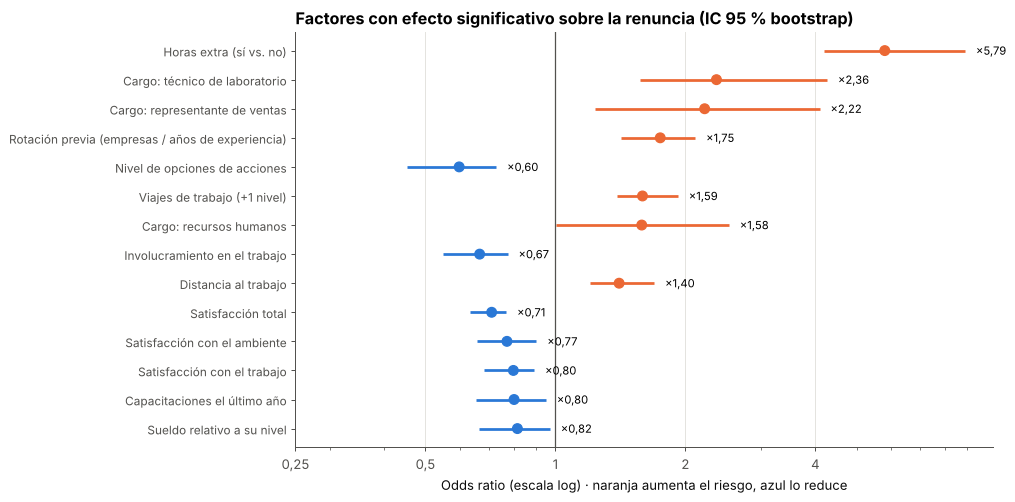

,OR,"IC 2,5 %","IC 97,5 %",significativo
horas_extra,5.79,4.19,8.89,True
JobRole_Laboratory Technician,2.36,1.57,4.26,True
JobRole_Sales Representative,2.22,1.24,4.09,True
rotacion_previa,1.75,1.42,2.11,True
StockOptionLevel,0.60,0.45,0.73,True
viajes,1.59,1.39,1.92,True
JobRole_Human Resources,1.58,1.01,2.52,True
JobInvolvement,0.67,0.55,0.77,True
DistanceFromHome,1.40,1.20,1.69,True
satisfaccion_total,0.71,0.64,0.77,True


In [11]:
redundantes = ["MonthlyIncome", "YearsInCurrentRole", "YearsWithCurrManager", "YearsSinceLastPromotion",
               "TotalWorkingYears", "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating"]
X_int = X.drop(columns=redundantes + protegidas)
print("VIF máximo tras depurar:", round(vif(X_int[[c for c in numericas if c in X_int.columns]]).max(), 2))

def coef_logit(Xd, yd):
    m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)).fit(Xd, yd)
    return m[-1].coef_[0]

binarias = [c for c in X_int.columns if set(X_int[c].unique()) <= {0, 1}]
Xs = X_int.copy()
for c in X_int.columns:
    if c not in binarias:
        Xs[c] = (X_int[c] - X_int[c].mean()) / X_int[c].std()
modelo_or = LogisticRegression(C=1.0, max_iter=5000).fit(Xs, y)
rng = np.random.default_rng(SEED)
boot = np.array([LogisticRegression(C=1.0, max_iter=5000).fit(Xs.iloc[i], y.iloc[i]).coef_[0]
                 for i in [rng.integers(0, len(y), len(y)) for _ in range(300)]])
ors = pd.DataFrame({"OR": np.exp(modelo_or.coef_[0]), "IC 2,5 %": np.exp(np.percentile(boot, 2.5, axis=0)),
                    "IC 97,5 %": np.exp(np.percentile(boot, 97.5, axis=0))}, index=Xs.columns)
ors["significativo"] = (ors["IC 2,5 %"] > 1) | (ors["IC 97,5 %"] < 1)
ors.to_csv(REP / "odds_ratios.csv")

nombres = {"horas_extra": "Horas extra (sí vs. no)", "viajes": "Viajes de trabajo (+1 nivel)",
           "EnvironmentSatisfaction": "Satisfacción con el ambiente", "JobSatisfaction": "Satisfacción con el trabajo",
           "JobInvolvement": "Involucramiento en el trabajo", "satisfaccion_total": "Satisfacción total",
           "StockOptionLevel": "Nivel de opciones de acciones", "JobLevel": "Nivel del cargo",
           "YearsAtCompany": "Años en la empresa", "estancamiento": "Estancamiento (años sin promoción / antigüedad)",
           "rotacion_previa": "Rotación previa (empresas / años de experiencia)", "DistanceFromHome": "Distancia al trabajo",
           "WorkLifeBalance": "Equilibrio vida-trabajo", "RelationshipSatisfaction": "Satisfacción con las relaciones",
           "sueldo_relativo_cargo": "Sueldo relativo a su nivel", "TrainingTimesLastYear": "Capacitaciones el último año",
           "JobRole_Sales Representative": "Cargo: representante de ventas", "Education": "Nivel educacional",
           "JobRole_Laboratory Technician": "Cargo: técnico de laboratorio", "JobRole_Human Resources": "Cargo: recursos humanos"}
top = ors[ors["significativo"]].copy()
top["dist"] = np.abs(np.log(top["OR"]))
top = top.sort_values("dist").tail(14)
fig, ax = plt.subplots(figsize=(10, 6))
yy = np.arange(len(top))
colores_or = [NARANJA if o > 1 else AZUL for o in top["OR"]]
ax.hlines(yy, top["IC 2,5 %"], top["IC 97,5 %"], color=colores_or, lw=2.2)
ax.scatter(top["OR"], yy, color=colores_or, s=60, zorder=3)
ax.axvline(1, color=TINTA2, lw=1)
ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(["0,25", "0,5", "1", "2", "4"])
ax.set_yticks(yy, [nombres.get(i, i.replace("_", " ")) for i in top.index], fontsize=9.5)
for i, o in enumerate(top["OR"]):
    ax.text(top["IC 97,5 %"].iloc[i] * 1.06, i, f"×{es(o, 2)}", va="center", fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds ratio (escala log) · naranja aumenta el riesgo, azul lo reduce")
ax.set_title("Factores con efecto significativo sobre la renuncia (IC 95 % bootstrap)")
guardar("04_odds_ratios")
top.drop(columns="dist").iloc[::-1].round(2)

**Lectura para el comité:**
- **Hacer horas extra multiplica las chances de renunciar casi 6 veces** (IC 95 %: 4,2 a 8,9), manteniendo todo lo demás constante. Es el factor más fuerte y es **controlable**.
- **Viajar más**, vivir **más lejos** y tener **más rotación previa** aumentan el riesgo; también ciertos cargos (técnicos de laboratorio y representantes de ventas, ~×2).
- La **satisfacción con el ambiente y el trabajo**, el **involucramiento**, las **opciones de acciones** y el **nivel del cargo** lo reducen.
- Estos efectos son **asociaciones**, no causas demostradas: sirven para priorizar hipótesis y diseñar pilotos, no como prueba definitiva.

## 6. Palancas accionables y costo de la rotación (PACE · Ejecutar)
### 6.1 ¿Qué puede cambiar la empresa?
Se separan las variables en **palancas** (la empresa puede actuar sobre ellas) y **contexto** (características de la persona que no se deben ni se pueden "corregir").

In [12]:
palancas = {"horas_extra", "viajes", "EnvironmentSatisfaction", "JobSatisfaction", "JobInvolvement", "StockOptionLevel",
            "WorkLifeBalance", "RelationshipSatisfaction", "satisfaccion_total", "estancamiento", "sueldo_relativo_cargo",
            "TrainingTimesLastYear", "JobLevel"}
contrib = (np.abs(modelo_or.coef_[0]) * Xs.std().values)
contrib = pd.Series(contrib, index=Xs.columns)
tipo = pd.Series(np.where(contrib.index.isin(palancas), "Palanca de gestión", "Contexto de la persona / del cargo"), index=contrib.index)
peso = contrib.groupby(tipo).sum() / contrib.sum()
print(peso.round(3))

# Escenario: ¿qué pasaría con la tasa de renuncia predicha si nadie hiciera horas extra? (asociativo, no causal)
modelo_final = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight=None, max_iter=5000)).fit(X_int, y)
p_actual = modelo_final.predict_proba(X_int)[:, 1]
X_esc = X_int.copy(); X_esc["horas_extra"] = 0
p_esc = modelo_final.predict_proba(X_esc)[:, 1]
print(f"\nTasa de renuncia predicha actual: {p_actual.mean():.1%} | escenario sin horas extra: {p_esc.mean():.1%}")
print(f"Renuncias anuales evitables estimadas: {es((p_actual - p_esc).sum())} de {es(y.sum())}")

Contexto de la persona / del cargo    0.399
Palanca de gestión                    0.601
dtype: float64

Tasa de renuncia predicha actual: 16.1% | escenario sin horas extra: 10.5%
Renuncias anuales evitables estimadas: 82 de 237


### 6.2 Costo de la rotación
**Supuesto (editable):** reemplazar a una persona cuesta el equivalente a **6 meses de su sueldo** (reclutamiento, inducción y productividad perdida). Es un supuesto conservador dentro de los rangos que suelen citarse en la literatura de RR.HH.

Costo estimado de las 237 renuncias observadas: USD 6.807.246
Costo asociado a las horas extra (escenario anterior): USD 2.548.290 (37%)


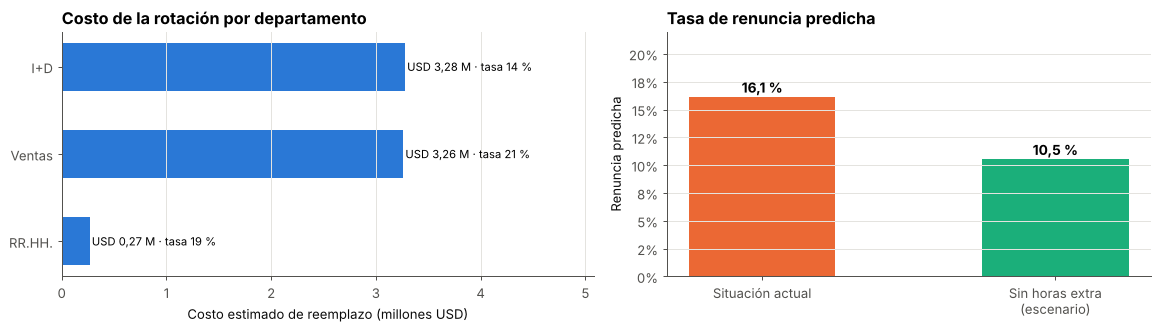

In [13]:
MESES_COSTO = 6
costo_ind = df["MonthlyIncome"] * MESES_COSTO
costo_total = costo_ind[df["renuncia"] == 1].sum()
evitables = ((p_actual - p_esc) * costo_ind.values).sum()
print(f"Costo estimado de las {y.sum()} renuncias observadas: USD {es(costo_total)}")
print(f"Costo asociado a las horas extra (escenario anterior): USD {es(evitables)} ({evitables/costo_total:.0%})")

dep = (pd.DataFrame({"Departamento": df["Department"].replace({"Research & Development": "I+D", "Sales": "Ventas",
                                                             "Human Resources": "RR.HH."}),
                     "renuncia": df["renuncia"], "costo": costo_ind * df["renuncia"]})
         .groupby("Departamento").agg(empleados=("renuncia", "size"), tasa=("renuncia", "mean"), costo=("costo", "sum")))
dep.to_csv(REP / "costo_por_departamento.csv")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
orden_dep = dep.sort_values("costo").index
a1.barh(orden_dep, dep.loc[orden_dep, "costo"] / 1e6, color=AZUL, height=0.55)
for i, d in enumerate(orden_dep):
    a1.text(dep.loc[d, "costo"] / 1e6 + 0.02, i, f"USD {es(dep.loc[d, 'costo']/1e6, 2)} M · tasa {dep.loc[d, 'tasa']*100:.0f} %",
            va="center", fontsize=9)
a1.set_xlim(0, dep["costo"].max() / 1e6 * 1.55); a1.grid(axis="y", visible=False)
a1.set_xlabel("Costo estimado de reemplazo (millones USD)"); a1.set_title("Costo de la rotación por departamento")
a2.bar(["Situación actual", "Sin horas extra\n(escenario)"], [p_actual.mean(), p_esc.mean()], color=[NARANJA, VERDE], width=0.5)
for i, v_ in enumerate([p_actual.mean(), p_esc.mean()]):
    a2.text(i, v_ + 0.004, f"{v_*100:.1f} %".replace(".", ","), ha="center", fontsize=11, fontweight="bold")
a2.set_ylim(0, 0.22); a2.yaxis.set_major_formatter(PCT); a2.grid(axis="x", visible=False)
a2.set_title("Tasa de renuncia predicha"); a2.set_ylabel("Renuncia predicha")
plt.tight_layout()
guardar("05_costo_escenario")

## 7. Auditoría de equidad: ¿hacen falta sexo, edad o estado civil?

ROC-AUC con variables protegidas: 0.825 | sin ellas: 0.819


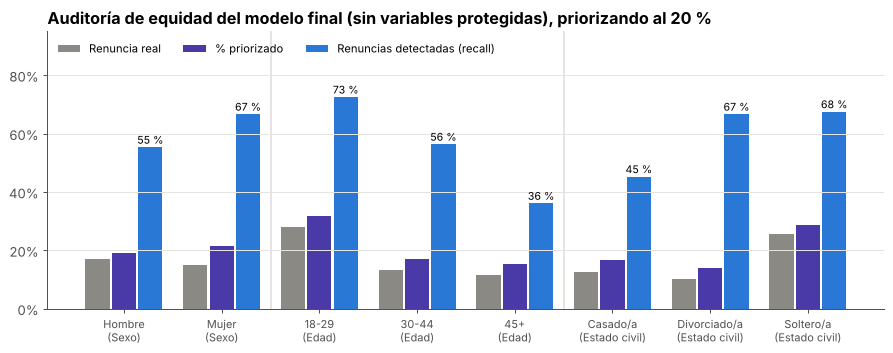

,Dimensión,Grupo,Empleados,Renuncia real,% priorizado,Renuncias detectadas (recall)
0,Sexo,Hombre,882,0.170,0.190,0.553
1,Sexo,Mujer,588,0.148,0.214,0.667
2,Edad,18-29,326,0.279,0.319,0.725
3,Edad,30-44,830,0.133,0.171,0.564
4,Edad,45+,314,0.115,0.153,0.361
5,Estado civil,Casado/a,673,0.125,0.168,0.452
6,Estado civil,Divorciado/a,327,0.101,0.141,0.667
7,Estado civil,Soltero/a,470,0.255,0.287,0.675


In [14]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
X_con = X.drop(columns=redundantes)
auc_con = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000)),
                          X_con, y, cv=rcv, scoring="roc_auc").mean()
auc_sin = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000)),
                          X_int, y, cv=rcv, scoring="roc_auc").mean()
print(f"ROC-AUC con variables protegidas: {auc_con:.3f} | sin ellas: {auc_sin:.3f}")

# Predicciones fuera de muestra del modelo final (sin protegidas) para auditar por grupo
p_oof = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000)),
                          X_int, y, cv=cv5, method="predict_proba")[:, 1]
corte = np.quantile(p_oof, 0.8)
aud = pd.DataFrame({"y": y.values, "prioriza": (p_oof >= corte).astype(int),
                    "Sexo": np.where(df["Gender"] == "Female", "Mujer", "Hombre"),
                    "Edad": pd.cut(df["Age"], [17, 29, 44, 70], labels=["18-29", "30-44", "45+"]).astype(str),
                    "Estado civil": df["MaritalStatus"].map({"Single": "Soltero/a", "Married": "Casado/a", "Divorced": "Divorciado/a"})})
filas = []
for dim in ["Sexo", "Edad", "Estado civil"]:
    for g, d in aud.groupby(dim):
        filas.append({"Dimensión": dim, "Grupo": g, "Empleados": len(d), "Renuncia real": d["y"].mean(),
                      "% priorizado": d["prioriza"].mean(), "Renuncias detectadas (recall)": d.loc[d.y == 1, "prioriza"].mean()})
equidad = pd.DataFrame(filas)
equidad.to_csv(REP / "auditoria_equidad.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4))
xx = np.arange(len(equidad)); w = 0.27
for k, (col, c) in enumerate([("Renuncia real", GRIS), ("% priorizado", VIOLETA), ("Renuncias detectadas (recall)", AZUL)]):
    ax.bar(xx + (k - 1) * w, equidad[col], w * 0.92, color=c, label=col)
for i, v_ in enumerate(equidad["Renuncias detectadas (recall)"]):
    ax.text(i + w, v_ + 0.012, f"{v_*100:.0f} %", ha="center", fontsize=8.5)
ax.set_xticks(xx, [f"{g}\n({d})" for d, g in zip(equidad["Dimensión"], equidad["Grupo"])], fontsize=8.8)
for sep in [1.5, 4.5]:
    ax.axvline(sep, color=GRILLA, lw=1.5)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, 0.95); ax.grid(axis="x", visible=False)
ax.set_title("Auditoría de equidad del modelo final (sin variables protegidas), priorizando al 20 %")
ax.legend(loc="upper left", ncols=3, fontsize=9)
guardar("06_equidad")
equidad.round(3)

**Lectura:**
- Quitar sexo, edad y estado civil **casi no cambia el rendimiento** (0,825 → 0,819), así que el modelo final los excluye.
- Aun sin usarlos, el modelo prioriza más a **jóvenes (18-29) y solteros**, porque su riesgo real es mayor (28 % y 26 %) y se expresa a través de variables de trabajo (nivel de cargo, opciones de acciones, horas extra). Como el uso definido es **ofrecer conversaciones de desarrollo**, esa focalización es aceptable.
- ⚠️ **Dos brechas a monitorear:** el modelo detecta el **67 % de las renuncias de mujeres vs. 55 % de hombres**, y solo el **36 % en mayores de 45 años**. Los hombres y los mayores que renuncian lo hacen por razones que los datos capturan peor. Recomendación: no depender solo del ranking del modelo y complementar con **entrevistas de permanencia** para todos los grupos.

Excluir una variable protegida no garantiza equidad por sí solo: por eso se audita el resultado por grupo.

## 8. 📋 Resumen ejecutivo de una página
El entregable final para la gerencia, generado directamente desde los resultados del análisis.

Resumen ejecutivo guardado en images/07_resumen_ejecutivo.png y reports/resumen_ejecutivo.pdf


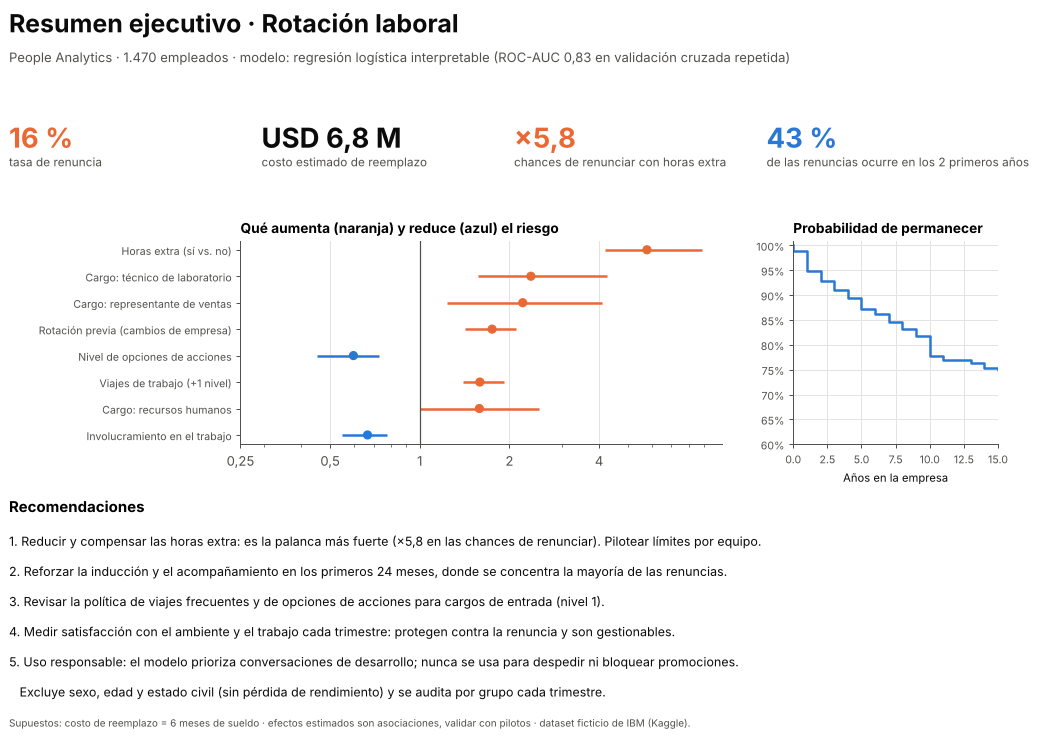

In [15]:
import matplotlib.gridspec as gridspec
fig = plt.figure(figsize=(11.69, 8.27))  # A4 horizontal
gs = gridspec.GridSpec(3, 3, figure=fig, height_ratios=[0.45, 1.3, 1.1], hspace=0.55, wspace=0.35,
                       left=0.25, right=0.97, top=0.88, bottom=0.06)
fig.text(0.03, 0.955, "Resumen ejecutivo · Rotación laboral", fontsize=20, fontweight="bold", color=TINTA)
fig.text(0.03, 0.915, f"People Analytics · {es(len(df))} empleados · modelo: regresión logística interpretable "
                      f"(ROC-AUC {es(aucs['Regresión logística'].mean(), 2)} en validación cruzada repetida)",
         fontsize=10.5, color=TINTA2)
kp = [(f"{df['renuncia'].mean()*100:.0f} %", "tasa de renuncia"),
      (f"USD {es(costo_total/1e6, 1)} M", "costo estimado de reemplazo"),
      (f"×{es(ors.loc['horas_extra', 'OR'], 1)}", "chances de renunciar con horas extra"),
      (f"{(df.loc[df.renuncia == 1, 'YearsAtCompany'] <= 2).mean()*100:.0f} %", "de las renuncias ocurre en los 2 primeros años")]
for i, (v_, t_txt) in enumerate(kp):
    x0 = 0.03 + i * 0.24
    fig.text(x0, 0.80, v_, fontsize=22, fontweight="bold", color=[NARANJA, TINTA, NARANJA, AZUL][i])
    fig.text(x0, 0.775, t_txt, fontsize=9.5, color=TINTA2)
a = fig.add_subplot(gs[1, :2])
t3 = top.sort_values("dist").tail(8)
yy = np.arange(len(t3)); cc = [NARANJA if o > 1 else AZUL for o in t3["OR"]]
a.hlines(yy, t3["IC 2,5 %"], t3["IC 97,5 %"], color=cc, lw=2); a.scatter(t3["OR"], yy, color=cc, s=40, zorder=3)
a.axvline(1, color=TINTA2, lw=1); a.set_xscale("log"); a.set_xticks([0.25, 0.5, 1, 2, 4]); a.set_xticklabels(["0,25", "0,5", "1", "2", "4"])
cortos = {"rotacion_previa": "Rotación previa (cambios de empresa)"}
a.set_yticks(yy, [cortos.get(i, nombres.get(i, i)) for i in t3.index], fontsize=8.5); a.grid(axis="y", visible=False)
a.set_title("Qué aumenta (naranja) y reduce (azul) el riesgo", fontsize=11)

b = fig.add_subplot(gs[1, 2])
b.step(km[:, 0], km[:, 1], where="post", color=AZUL, lw=2)
b.set_xlim(0, 15); b.set_ylim(0.6, 1.01); b.yaxis.set_major_formatter(PCT); b.set_xlabel("Años en la empresa", fontsize=9)
b.set_title("Probabilidad de permanecer", fontsize=11); b.tick_params(labelsize=8.5)

c = fig.add_axes([0.03, 0.06, 0.94, 0.27]); c.axis("off")
recs = [f"1. Reducir y compensar las horas extra: es la palanca más fuerte (×{es(ors.loc['horas_extra', 'OR'], 1)} en las chances de renunciar). Pilotear límites por equipo.",
        "2. Reforzar la inducción y el acompañamiento en los primeros 24 meses, donde se concentra la mayoría de las renuncias.",
        "3. Revisar la política de viajes frecuentes y de opciones de acciones para cargos de entrada (nivel 1).",
        "4. Medir satisfacción con el ambiente y el trabajo cada trimestre: protegen contra la renuncia y son gestionables.",
        "5. Uso responsable: el modelo prioriza conversaciones de desarrollo; nunca se usa para despedir ni bloquear promociones.",
        "   Excluye sexo, edad y estado civil (sin pérdida de rendimiento) y se audita por grupo cada trimestre."]
c.text(0, 1.0, "Recomendaciones", fontsize=12, fontweight="bold", va="top", transform=c.transAxes)
for i, r in enumerate(recs):
    c.text(0, 0.82 - i * 0.15, r, fontsize=10, va="top", transform=c.transAxes, color=TINTA)
c.text(0, -0.14, "Supuestos: costo de reemplazo = 6 meses de sueldo · efectos estimados son asociaciones, validar con pilotos · "
                 "dataset ficticio de IBM (Kaggle).", fontsize=8, color=TINTA2, transform=c.transAxes)
plt.savefig(IMG / "07_resumen_ejecutivo.png", facecolor="white", dpi=160)
plt.savefig(REP / "resumen_ejecutivo.pdf", facecolor="white")
plt.show()
print("Resumen ejecutivo guardado en images/07_resumen_ejecutivo.png y reports/resumen_ejecutivo.pdf")

## 9. Conclusiones

**Hallazgos**
1. **La auditoría importa:** 3 columnas constantes y 3 "tarifas" que no se relacionan con el sueldo se habrían colado como variables.
2. **El riesgo se concentra en los primeros años**, y la brecha de las horas extra aparece desde el primer año.
3. **La regresión logística iguala o supera a Random Forest y XGBoost** con estos datos, y es la más fácil de explicar.
4. **Con 1.470 filas, un solo split puede dar un ROC-AUC entre 0,74 y 0,89**: la validación cruzada repetida es obligatoria.
5. **Horas extra, viajes, satisfacción, involucramiento y opciones de acciones** son palancas gestionables con efectos significativos.
6. **Sexo, edad y estado civil no hacen falta** para el modelo.

**Limitaciones**
- Dataset ficticio creado por IBM: los patrones son ilustrativos.
- Los efectos son asociaciones; el escenario "sin horas extra" no es una predicción causal y debe validarse con pilotos.
- Siguiente nivel: modelos de supervivencia completos (Cox) para predecir **cuándo** ocurrirá la renuncia.